# Exercise 3 — Multi-Class Classification

The same `MLP` class from Exercise 2, unchanged: only the output size, the output
activation (softmax) and the loss (categorical cross-entropy) are different
arguments. The forward pass, backward pass and update are the same code.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from mlp import MLP

%matplotlib inline

FIG_DIR = Path("..") / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

rng = np.random.default_rng(42)

## A — Generate the data

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=1500, n_features=4, n_informative=4,
                           n_redundant=0, n_repeated=0, n_classes=3,
                           n_clusters_per_class=2, class_sep=1.0,
                           random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape)

train: (1200, 4) | test: (300, 4)


## C — Train and evaluate

Architecture `[4, 16, 3]`: 4 inputs, one hidden layer of 16 tanh units, 3 softmax
outputs; categorical cross-entropy; full-batch gradient descent.

In [3]:
ARCH, LR, EPOCHS = [4, 16, 3], 0.5, 2000

model = MLP(ARCH, rng, output="softmax")
losses = model.fit(X_train, y_train, epochs=EPOCHS, lr=LR)
test_acc = model.accuracy(X_test, y_test)
print(f"architecture = {ARCH}, lr = {LR}, epochs = {EPOCHS}, params = {model.n_params()}")
print(f"final training loss = {losses[-1]:.4f}")
print(f"train accuracy = {model.accuracy(X_train, y_train):.4f}")
print(f"test accuracy  = {test_acc:.4f}")

baseline_acc = LogisticRegression(max_iter=1000).fit(X_train, y_train).score(X_test, y_test)
print(f"logistic-regression baseline test accuracy = {baseline_acc:.4f}")

architecture = [4, 16, 3], lr = 0.5, epochs = 2000, params = 131
final training loss = 0.2597
train accuracy = 0.9050
test accuracy  = 0.8567
logistic-regression baseline test accuracy = 0.6633


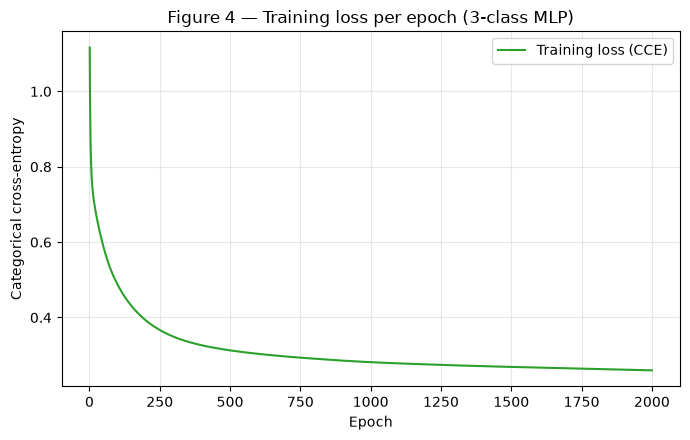

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, EPOCHS + 1), losses, color="#2ca02c", label="Training loss (CCE)")
ax.set_title("Figure 4 — Training loss per epoch (3-class MLP)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Categorical cross-entropy")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_multiclass_loss.png", dpi=150)
plt.show()

[[90  6  4]
 [12 77 11]
 [ 5  5 90]]


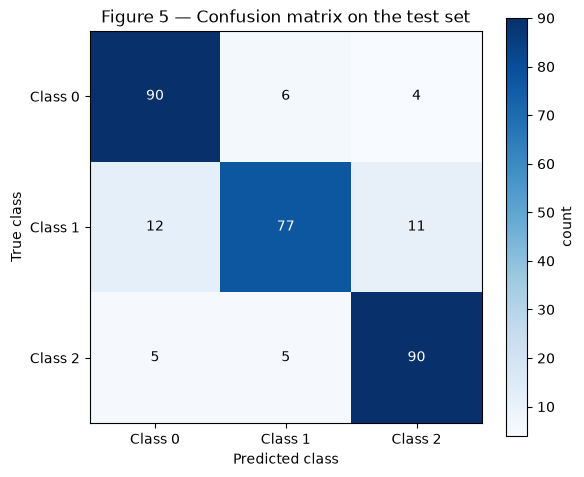

classes 0 <-> 1: 18 confusions
classes 0 <-> 2: 9 confusions
classes 1 <-> 2: 16 confusions
most-confused pair: (0, 1) (18 test points)


In [5]:
cm = confusion_matrix(y_test, model.predict(X_test))
print(cm)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(3), labels=[f"Class {k}" for k in range(3)])
ax.set_yticks(range(3), labels=[f"Class {k}" for k in range(3)])
ax.set_title("Figure 5 — Confusion matrix on the test set")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
fig.colorbar(im, ax=ax, label="count")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_confusion.png", dpi=150)
plt.show()

pairs = {(i, j): int(cm[i, j] + cm[j, i]) for i in range(3) for j in range(i + 1, 3)}
for (i, j), n in pairs.items():
    print(f"classes {i} <-> {j}: {n} confusions")
worst = max(pairs, key=pairs.get)
print(f"most-confused pair: {worst} ({pairs[worst]} test points)")